In [1]:
%pip install tensorflow pandas numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D
from tensorflow.keras.layers import Dense, Dropout

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [3]:
num_words = 10000

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=num_words
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

print("\nFirst review (encoded):")
print(X_train[0][:30])

print("\nSentiment label:", y_train[0])

Training reviews: 25000
Testing reviews: 25000

First review (encoded):
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480]

Sentiment label: 1


In [4]:
max_length = 150

X_train = pad_sequences(
    X_train,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    X_test,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (25000, 150)
Testing shape: (25000, 150)


In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, Conv1D
from tensorflow.keras.layers import GlobalMaxPooling1D, Dense, Dropout

model = Sequential([
    Input(shape=(max_length,)),

    Embedding(
        input_dim=num_words,
        output_dim=64
    ),

    Conv1D(
        filters=64,
        kernel_size=5,
        activation="relu"
    ),

    GlobalMaxPooling1D(),

    Dropout(0.5),

    Dense(32, activation="relu"),

    Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 150, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 146, 64)        │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 662,657 (2.53 MB)

 Trainable params: 662,657 (2.53 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [7]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6946 - loss: 0.5638 - val_accuracy: 0.8162 - val_loss: 0.4127
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8491 - loss: 0.3563 - val_accuracy: 0.8446 - val_loss: 0.3609
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9112 - loss: 0.2352 - val_accuracy: 0.8364 - val_loss: 0.3883
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9492 - loss: 0.1456 - val_accuracy: 0.8392 - val_loss: 0.4408
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9678 - loss: 0.0940 - val_accuracy: 0.8326 - val_loss: 0.5418


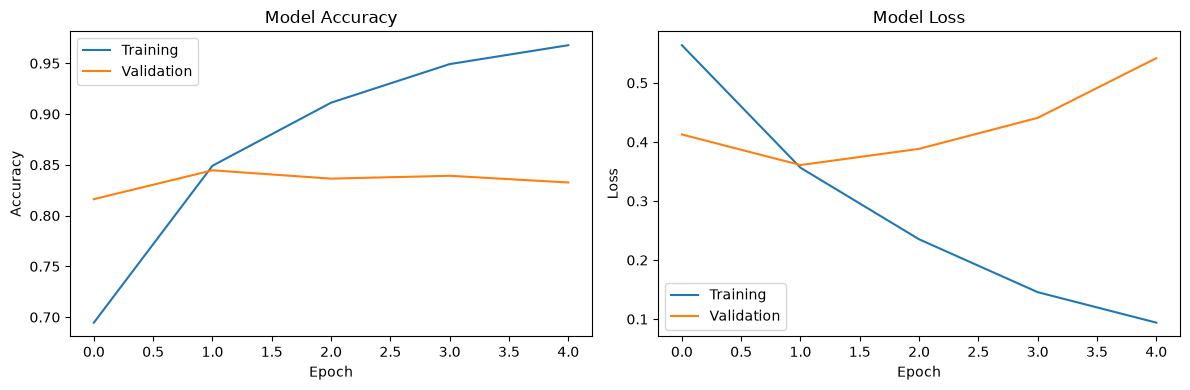

In [8]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [9]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=32,
    verbose=1
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8199 - loss: 0.5721
Test Loss: 0.5721
Test Accuracy: 81.99 %


782/782 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step  
              precision    recall  f1-score   support

    Negative       0.83      0.80      0.82     12500
    Positive       0.81      0.84      0.82     12500

    accuracy                           0.82     25000
   macro avg       0.82      0.82      0.82     25000
weighted avg       0.82      0.82      0.82     25000



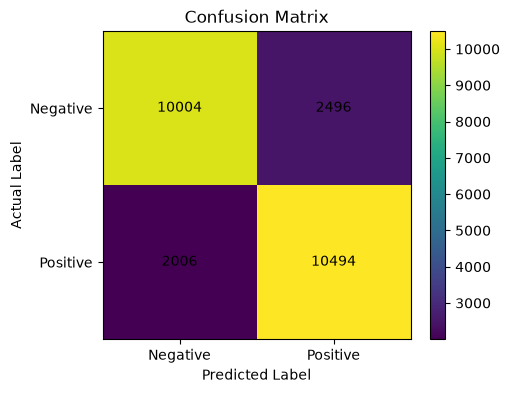

In [10]:
y_prob = model.predict(X_test, batch_size=32, verbose=1)
y_pred = (y_prob >= 0.5).astype(int).flatten()

print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks([0, 1], ["Negative", "Positive"])
plt.yticks([0, 1], ["Negative", "Positive"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.colorbar()
plt.show()

In [24]:
word_index = imdb.get_word_index()

def encode_review(text):
    words = text.lower().split()
    sequence = [1]  # Start-of-review token

    for word in words:
        word = "".join(ch for ch in word if ch.isalpha())

        if word:
            index = word_index.get(word, 2) + 3

            if index >= num_words:
                index = 2

            sequence.append(index)

    return pad_sequences(
        [sequence],
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

def predict_sentiment(review):
    encoded = encode_review(review)
    probability = float(model.predict(encoded, verbose=0)[0][0])

    sentiment = "Positive" if probability >= 0.5 else "Negative"

    print("Review:", review)
    print("Sentiment:", sentiment)
    print("Positive probability:", round(probability * 100, 2), "%")

predict_sentiment("This movie was amazing and I really loved it")

predict_sentiment("This movie was boring and a complete waste of time")

Review: This movie was amazing and I really loved it
Sentiment: Positive
Positive probability: 99.85 %
Review: This movie was boring and a complete waste of time
Sentiment: Negative
Positive probability: 0.02 %


In [27]:
model.save("sentiment_cnn_model.keras")
print("Model saved successfully!")

Model saved successfully!
